# Digital Image Processing — Lab Task 04

## Geometric Transformations with Custom Inputs

**Student Name:** Danial Ayub Mughal

**Roll Number:** 2024-SE-20

**Course:** Digital Image Processing Lab

**Lab Task:** 04 — Geometric Transformations with Custom Inputs


### Objective
Create a reusable `transform()` function that accepts an image, an operation name, and custom parameters; validates the image and parameters; and returns the transformed image.



## Task 1 — Import libraries and define project settings

In [1]:
import sys
!{sys.executable} -m pip install opencv-python

In [2]:
import os
import math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "outputs"
MAX_OUTPUT_WIDTH = 12000
MAX_OUTPUT_HEIGHT = 12000
MAX_OUTPUT_PIXELS = 40_000_000

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Libraries imported successfully.")
print("OpenCV version:", cv2.__version__)
print("Output folder:", os.path.abspath(OUTPUT_DIR))

Libraries imported successfully.
OpenCV version: 5.0.0
Output folder: C:\Users\ASAA\Lab 04\outputs


## Task 2 — Load and validate the input image

In [3]:
IMAGE_PATH = os.path.join("images", "input.jpg")  # Change this path if required

if not os.path.isfile(IMAGE_PATH):
    raise FileNotFoundError(
        f"Image file not found: {IMAGE_PATH}. Put an image in the images folder "
        "or update IMAGE_PATH."
    )

original = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)

if original is None:
    raise ValueError("The file exists, but OpenCV could not decode it. Try a valid JPG or PNG image.")

if original.ndim != 3 or original.shape[2] != 3:
    raise ValueError("Expected a three-channel colour image.")

height, width = original.shape[:2]
if width <= 0 or height <= 0:
    raise ValueError("Image width and height must be greater than zero.")

print("Image loaded successfully.")
print("Width:", width, "pixels")
print("Height:", height, "pixels")
print("Array shape (height, width, channels):", original.shape)
print("Data type:", original.dtype)

Image loaded successfully.
Width: 736 pixels
Height: 736 pixels
Array shape (height, width, channels): (736, 736, 3)
Data type: uint8


## Task 3 — Display the original image

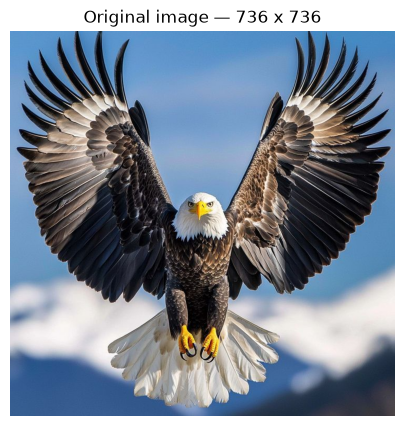

In [4]:
def show_image(image, title="Image", figsize=(7, 5)):
    """Display an OpenCV BGR image correctly with Matplotlib."""
    if image is None:
        raise ValueError("Cannot display an empty image.")
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(rgb)
    plt.title(title)
    plt.axis("off")
    plt.show()

show_image(original, f"Original image — {width} x {height}")

## Task 4 — Reusable transformation function



In [5]:
INTERPOLATIONS = {
    "nearest": cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic": cv2.INTER_CUBIC,
    "lanczos": cv2.INTER_LANCZOS4,
}

def _finite_number(value, name):
    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be a numeric value.")
    if not math.isfinite(number):
        raise ValueError(f"{name} must be finite (not NaN or infinity).")
    return number

def _integer(value, name):
    if isinstance(value, (bool, np.bool_)):
        raise ValueError(f"{name} must be an integer coordinate.")
    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be an integer coordinate.")
    if not math.isfinite(number) or not number.is_integer():
        raise ValueError(f"{name} must be an integer coordinate.")
    return int(number)

def _validate_image(image):
    if not isinstance(image, np.ndarray):
        raise ValueError("Image must be a NumPy array.")
    if image.size == 0 or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Image must be a non-empty three-channel BGR image.")
    h, w = image.shape[:2]
    if h <= 0 or w <= 0:
        raise ValueError("Image dimensions must be greater than zero.")
    return h, w

def _check_output_size(width, height):
    if width < 1 or height < 1:
        raise ValueError("Transformation would produce an empty image.")
    if width > MAX_OUTPUT_WIDTH or height > MAX_OUTPUT_HEIGHT:
        raise ValueError("Output dimensions exceed the maximum allowed width or height.")
    if width * height > MAX_OUTPUT_PIXELS:
        raise ValueError("Output image exceeds the maximum allowed pixel count.")

def transform(image, operation, **params):
    """Return a transformed BGR image after validating operation and parameters."""
    h, w = _validate_image(image)
    if not isinstance(operation, str):
        raise ValueError("Operation name must be text.")
    operation = operation.strip().lower()

    if operation == "scale":
        required = {"sx", "sy", "interpolation"}
        missing = required - params.keys()
        if missing:
            raise ValueError(f"Missing scale parameter(s): {', '.join(sorted(missing))}")
        sx = _finite_number(params["sx"], "sx")
        sy = _finite_number(params["sy"], "sy")
        if sx <= 0 or sy <= 0:
            raise ValueError("Scale factors sx and sy must be greater than zero.")
        interpolation = str(params["interpolation"]).strip().lower()
        if interpolation not in INTERPOLATIONS:
            raise ValueError(f"Unsupported interpolation. Choose one of: {', '.join(INTERPOLATIONS)}")
        new_w = int(round(w * sx))
        new_h = int(round(h * sy))
        _check_output_size(new_w, new_h)
        return cv2.resize(image, (new_w, new_h), interpolation=INTERPOLATIONS[interpolation])

    elif operation == "crop":
        required = {"left", "top", "right", "bottom"}
        missing = required - params.keys()
        if missing:
            raise ValueError(f"Missing crop parameter(s): {', '.join(sorted(missing))}")
        left = _integer(params["left"], "left")
        top = _integer(params["top"], "top")
        right = _integer(params["right"], "right")
        bottom = _integer(params["bottom"], "bottom")
        if not (0 <= left < right <= w):
            raise ValueError(f"Require 0 <= left < right <= image width ({w}).")
        if not (0 <= top < bottom <= h):
            raise ValueError(f"Require 0 <= top < bottom <= image height ({h}).")
        result = image[top:bottom, left:right].copy()  # right and bottom are exclusive
        _check_output_size(result.shape[1], result.shape[0])
        return result

    elif operation == "flip":
        if "direction" not in params:
            raise ValueError("Missing flip parameter: direction.")
        direction = str(params["direction"]).strip().lower()
        flip_codes = {"horizontal": 1, "vertical": 0, "both": -1}
        if direction not in flip_codes:
            raise ValueError("Unsupported flip direction. Use horizontal, vertical, or both.")
        return cv2.flip(image, flip_codes[direction])

    elif operation == "translate":
        required = {"tx", "ty"}
        missing = required - params.keys()
        if missing:
            raise ValueError(f"Missing translation parameter(s): {', '.join(sorted(missing))}")
        tx = _finite_number(params["tx"], "tx")
        ty = _finite_number(params["ty"], "ty")
        matrix = np.float32([[1, 0, tx], [0, 1, ty]])
        # Same width and height: pixels shifted outside are clipped; uncovered areas are black.
        return cv2.warpAffine(image, matrix, (w, h), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

    elif operation == "rotate":
        required = {"angle", "expand"}
        missing = required - params.keys()
        if missing:
            raise ValueError(f"Missing rotation parameter(s): {', '.join(sorted(missing))}")
        angle = _finite_number(params["angle"], "angle")
        expand = params["expand"]
        if not isinstance(expand, (bool, np.bool_)):
            raise ValueError("expand must be True or False.")
        center = (w / 2.0, h / 2.0)
        matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        if expand:
            cosine = abs(matrix[0, 0])
            sine = abs(matrix[0, 1])
            new_w = int(math.ceil((h * sine) + (w * cosine)))
            new_h = int(math.ceil((h * cosine) + (w * sine)))
            matrix[0, 2] += (new_w / 2.0) - center[0]
            matrix[1, 2] += (new_h / 2.0) - center[1]
        else:
            new_w, new_h = w, h
        _check_output_size(new_w, new_h)
        return cv2.warpAffine(image, matrix, (new_w, new_h),
                              flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT,
                              borderValue=(0, 0, 0))

    else:
        raise ValueError(
            f"Unknown operation '{operation}'. Use scale, crop, flip, translate, or rotate."
        )

## Task 5 — Scaling / resizing (enlargement, reduction, proportional and non-proportional)

Original dimensions: 736 x 736
Enlarged dimensions: 1104 x 1104
Reduced dimensions: 368 x 368
Non-proportional dimensions: 1104 x 589


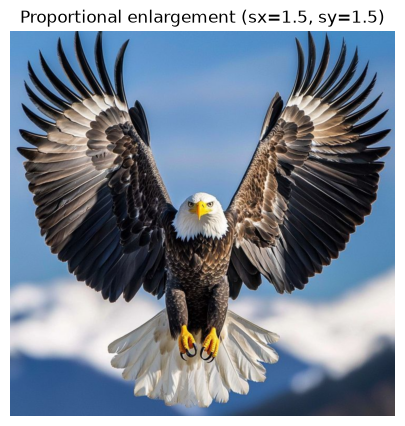

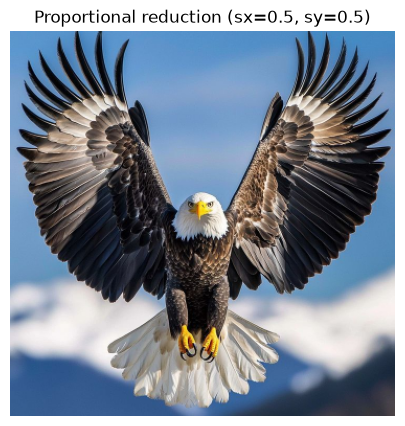

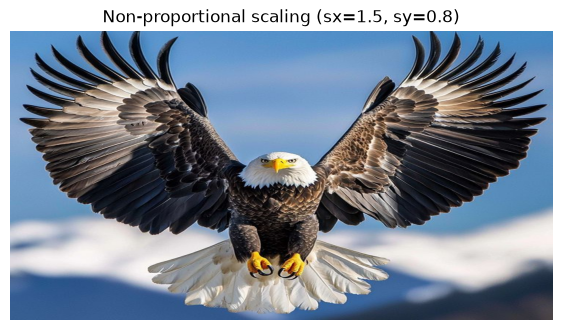

In [6]:
# Custom demonstration values
enlarged = transform(original, "scale", sx=1.5, sy=1.5, interpolation="bilinear")
reduced = transform(original, "scale", sx=0.5, sy=0.5, interpolation="bilinear")
non_proportional = transform(original, "scale", sx=1.5, sy=0.8, interpolation="bicubic")

print("Original dimensions:", original.shape[1], "x", original.shape[0])
print("Enlarged dimensions:", enlarged.shape[1], "x", enlarged.shape[0])
print("Reduced dimensions:", reduced.shape[1], "x", reduced.shape[0])
print("Non-proportional dimensions:", non_proportional.shape[1], "x", non_proportional.shape[0])

show_image(enlarged, "Proportional enlargement (sx=1.5, sy=1.5)")
show_image(reduced, "Proportional reduction (sx=0.5, sy=0.5)")
show_image(non_proportional, "Non-proportional scaling (sx=1.5, sy=0.8)")

## Task 6 — Cropping with custom coordinates

Crop coordinates: left=184, top=184, right=552, bottom=552
Cropped dimensions: 368 x 368


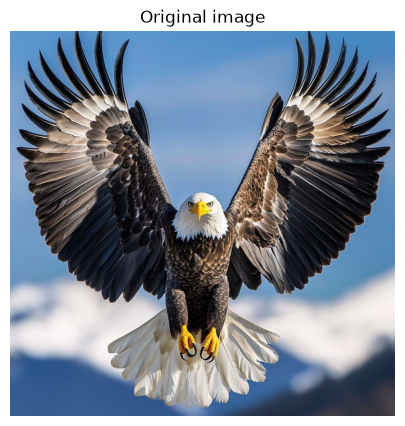

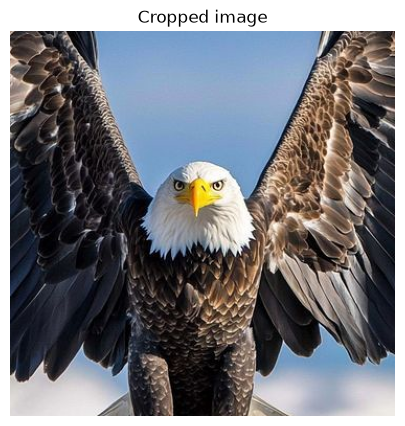

In [7]:
# A central crop using values calculated from the loaded image dimensions
left = width // 4
top = height // 4
right = (3 * width) // 4
bottom = (3 * height) // 4

cropped = transform(original, "crop", left=left, top=top, right=right, bottom=bottom)
print(f"Crop coordinates: left={left}, top={top}, right={right}, bottom={bottom}")
print("Cropped dimensions:", cropped.shape[1], "x", cropped.shape[0])
show_image(original, "Original image")
show_image(cropped, "Cropped image")

## Task 7 — Flipping (horizontal, vertical, and both)

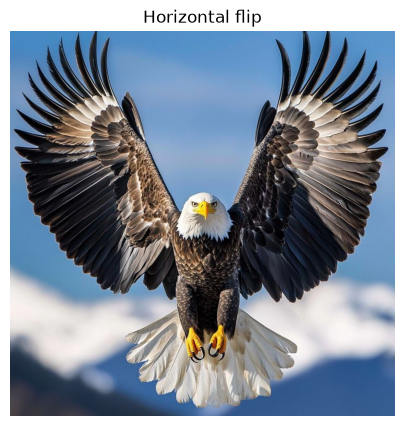

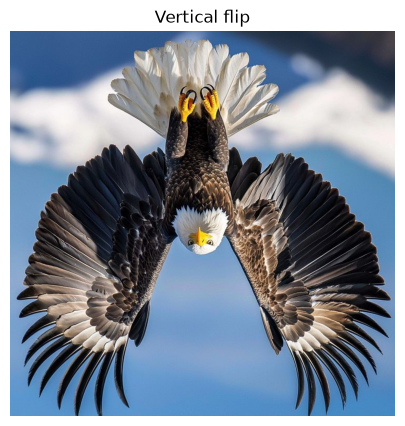

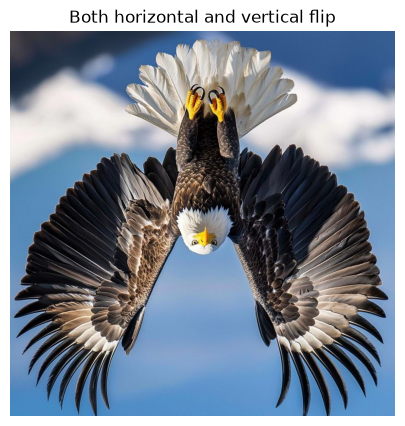

In [8]:
flip_horizontal = transform(original, "flip", direction="horizontal")
flip_vertical = transform(original, "flip", direction="vertical")
flip_both = transform(original, "flip", direction="both")

show_image(flip_horizontal, "Horizontal flip")
show_image(flip_vertical, "Vertical flip")
show_image(flip_both, "Both horizontal and vertical flip")

## Task 8 — Translation (positive and negative shifts)

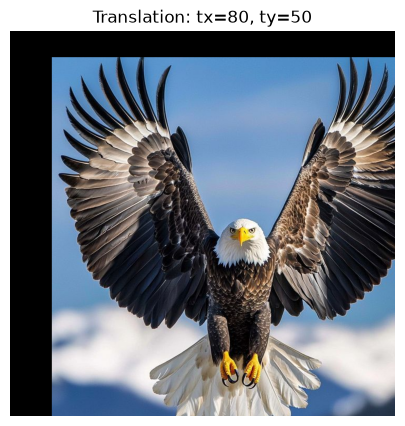

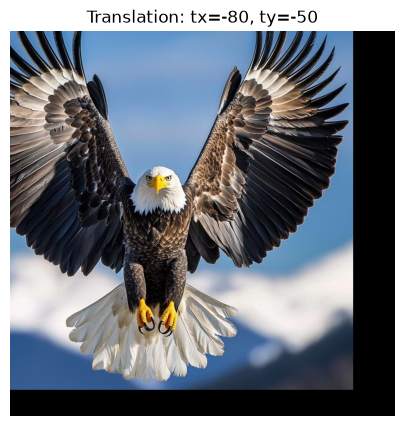

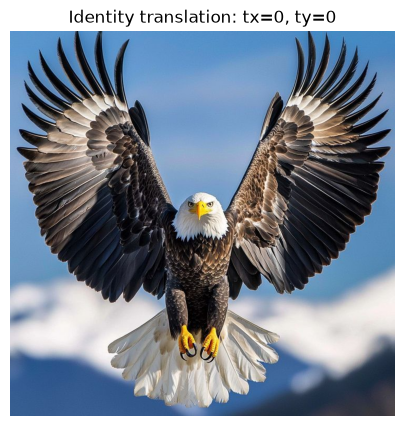

In [9]:
shift_right_down = transform(original, "translate", tx=80, ty=50)
shift_left_up = transform(original, "translate", tx=-80, ty=-50)
zero_translation = transform(original, "translate", tx=0, ty=0)

show_image(shift_right_down, "Translation: tx=80, ty=50")
show_image(shift_left_up, "Translation: tx=-80, ty=-50")
show_image(zero_translation, "Identity translation: tx=0, ty=0")

## Task 9 — Rotation (positive and negative angles; expanded and fixed canvas)

Original: 736 x 736
Positive rotation, fixed canvas: 736 x 736
Negative rotation, fixed canvas: 736 x 736
Positive rotation, expanded canvas: 1006 x 1006


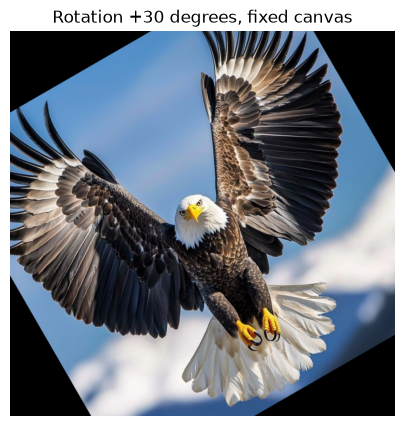

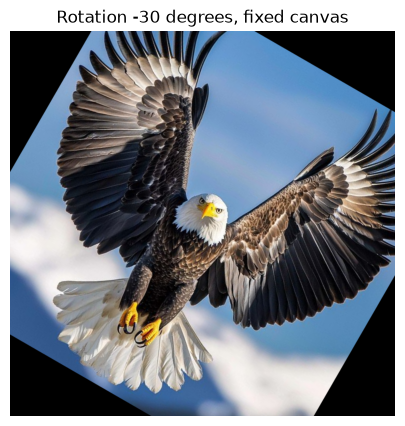

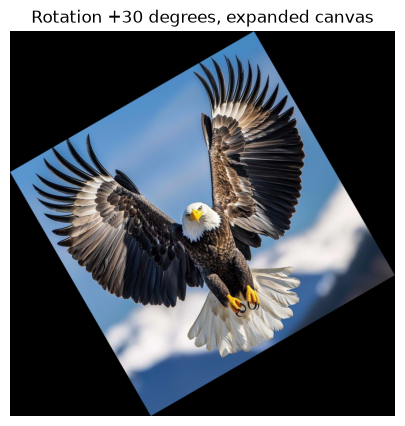

In [10]:
rotated_positive = transform(original, "rotate", angle=30, expand=False)
rotated_negative = transform(original, "rotate", angle=-30, expand=False)
rotated_expanded = transform(original, "rotate", angle=30, expand=True)

print("Original:", width, "x", height)
print("Positive rotation, fixed canvas:", rotated_positive.shape[1], "x", rotated_positive.shape[0])
print("Negative rotation, fixed canvas:", rotated_negative.shape[1], "x", rotated_negative.shape[0])
print("Positive rotation, expanded canvas:", rotated_expanded.shape[1], "x", rotated_expanded.shape[0])

show_image(rotated_positive, "Rotation +30 degrees, fixed canvas")
show_image(rotated_negative, "Rotation -30 degrees, fixed canvas")
show_image(rotated_expanded, "Rotation +30 degrees, expanded canvas")

## Task 10 — Compare interpolation methods on the same enlarged image patch

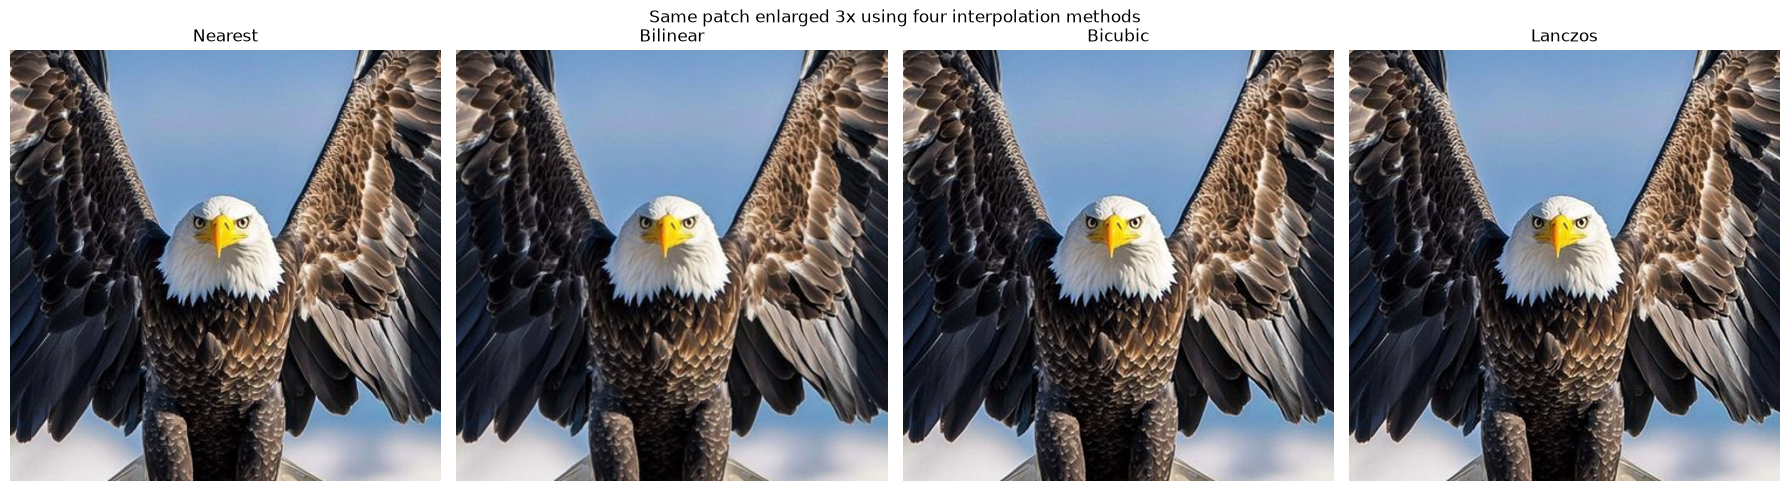

In [11]:
# Select a patch from the centre, then enlarge it using all four methods.
patch_left = width // 4
patch_top = height // 4
patch_right = max(patch_left + 1, (3 * width) // 4)
patch_bottom = max(patch_top + 1, (3 * height) // 4)
patch = transform(original, "crop", left=patch_left, top=patch_top,
                  right=patch_right, bottom=patch_bottom)

interpolation_results = {}
for method in ["nearest", "bilinear", "bicubic", "lanczos"]:
    interpolation_results[method] = transform(
        patch, "scale", sx=3.0, sy=3.0, interpolation=method
    )

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (method, result) in zip(axes, interpolation_results.items()):
    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax.set_title(method.capitalize())
    ax.axis("off")
plt.suptitle("Same patch enlarged 3x using four interpolation methods")
plt.tight_layout()
plt.show()

## Task 11 — User input through notebook prompts

In [ ]:
def ask_float(prompt):
    text_value = input(prompt).strip()
    if text_value.lower() == "q":
        raise KeyboardInterrupt("Input cancelled by user.")
    try:
        value = float(text_value)
    except ValueError:
        raise ValueError("Please enter a numeric value.")
    if not math.isfinite(value):
        raise ValueError("Please enter a finite number (not NaN or infinity).")
    return value

def ask_int(prompt):
    text_value = input(prompt).strip()
    if text_value.lower() == "q":
        raise KeyboardInterrupt("Input cancelled by user.")
    try:
        value = int(text_value)
    except ValueError:
        raise ValueError("Please enter a whole-number integer.")
    return value

def interactive_transformation():
    print("Available operations: scale, crop, flip, translate, rotate")
    operation = input("Choose operation (or q to cancel): ").strip().lower()
    if operation == "q":
        print("Cancelled.")
        return
    try:
        if operation == "scale":
            sx = ask_float("Horizontal scale factor sx: ")
            sy = ask_float("Vertical scale factor sy: ")
            method = input("Interpolation (nearest/bilinear/bicubic/lanczos): ").strip().lower()
            result = transform(original, "scale", sx=sx, sy=sy, interpolation=method)
            details = f"sx={sx}, sy={sy}, interpolation={method}"
        elif operation == "crop":
            left = ask_int("Left: ")
            top = ask_int("Top: ")
            right = ask_int("Right (exclusive): ")
            bottom = ask_int("Bottom (exclusive): ")
            result = transform(original, "crop", left=left, top=top, right=right, bottom=bottom)
            details = f"left={left}, top={top}, right={right}, bottom={bottom}"
        elif operation == "flip":
            direction = input("Direction (horizontal/vertical/both): ").strip().lower()
            result = transform(original, "flip", direction=direction)
            details = f"direction={direction}"
        elif operation == "translate":
            tx = ask_float("Horizontal offset tx: ")
            ty = ask_float("Vertical offset ty: ")
            result = transform(original, "translate", tx=tx, ty=ty)
            details = f"tx={tx}, ty={ty}"
        elif operation == "rotate":
            angle = ask_float("Angle in degrees: ")
            expand_text = input("Expand canvas? (yes/no): ").strip().lower()
            if expand_text not in {"yes", "no"}:
                raise ValueError("Canvas expansion must be yes or no.")
            expand = expand_text == "yes"
            result = transform(original, "rotate", angle=angle, expand=expand)
            details = f"angle={angle}, expand={expand}"
        else:
            raise ValueError("Unknown operation. Choose scale, crop, flip, translate, or rotate.")

        show_image(result, f"{operation}: {details}")
        print("Output dimensions:", result.shape[1], "x", result.shape[0])
        save_name = f"interactive_{operation}.png"
        save_path = os.path.join(OUTPUT_DIR, save_name)
        if not cv2.imwrite(save_path, result):
            raise IOError(f"Could not save result to {save_path}")
        print("Saved:", save_path)
    except KeyboardInterrupt as error:
        print(error)
    except (ValueError, IOError) as error:
        print("Input/operation error:", error)
        print("Correct the input and run this cell again.")

interactive_transformation()

Available operations: scale, crop, flip, translate, rotate


## Task 12 — Demonstrate rejected inputs for every operation

In [ ]:
def show_rejection(label, function):
    try:
        function()
        print(f"FAIL — {label}: invalid input was not rejected.")
    except (ValueError, TypeError) as error:
        print(f"PASS — {label}: {error}")

show_rejection("Scale factor zero",
               lambda: transform(original, "scale", sx=0, sy=1, interpolation="bilinear"))
show_rejection("Invalid crop coordinates",
               lambda: transform(original, "crop", left=10, top=10, right=5, bottom=20))
show_rejection("Unsupported flip direction",
               lambda: transform(original, "flip", direction="diagonal"))
show_rejection("Infinite translation offset",
               lambda: transform(original, "translate", tx=float("inf"), ty=0))
show_rejection("Nonnumeric rotation angle",
               lambda: transform(original, "rotate", angle="not-an-angle", expand=False))
show_rejection("Unsupported interpolation",
               lambda: transform(original, "scale", sx=2, sy=2, interpolation="unknown"))
show_rejection("Unknown operation",
               lambda: transform(original, "shear"))

## Task 13 — Identity checks (zero translation, scale factors one, zero rotation)

In [ ]:
identity_cases = [
    ("Translation tx=0, ty=0",
     original, transform(original, "translate", tx=0, ty=0)),
    ("Scaling sx=1, sy=1",
     original, transform(original, "scale", sx=1, sy=1, interpolation="nearest")),
    ("Rotation angle=0",
     original, transform(original, "rotate", angle=0, expand=False)),
]

identity_rows = []
for name, expected, actual in identity_cases:
    passed = expected.shape == actual.shape and np.array_equal(expected, actual)
    identity_rows.append({
        "Test": name,
        "Expected behaviour": "Image unchanged",
        "Actual behaviour": "Image unchanged" if passed else "Image differs",
        "Result": "PASS" if passed else "FAIL"
    })

identity_table = pd.DataFrame(identity_rows)
display(identity_table)

## Task 14 — Compare original and transformed images; save all results

In [ ]:
results_to_save = {
    "scale_enlarged.png": enlarged,
    "scale_reduced.png": reduced,
    "scale_non_proportional.png": non_proportional,
    "crop.png": cropped,
    "flip_horizontal.png": flip_horizontal,
    "flip_vertical.png": flip_vertical,
    "flip_both.png": flip_both,
    "translate_right_down.png": shift_right_down,
    "translate_left_up.png": shift_left_up,
    "rotate_positive.png": rotated_positive,
    "rotate_negative.png": rotated_negative,
    "rotate_expanded.png": rotated_expanded,
    "interpolation_nearest.png": interpolation_results["nearest"],
    "interpolation_bilinear.png": interpolation_results["bilinear"],
    "interpolation_bicubic.png": interpolation_results["bicubic"],
    "interpolation_lanczos.png": interpolation_results["lanczos"],
}

for filename, result in results_to_save.items():
    destination = os.path.join(OUTPUT_DIR, filename)
    if not cv2.imwrite(destination, result):
        raise IOError(f"Could not save {destination}")
    print(f"Saved {destination} — {result.shape[1]} x {result.shape[0]}")

print("\nTotal saved demonstration images:", len(results_to_save))

## Task 15 — Short conceptual explanations

### 1. Image coordinates versus array indexing
Image coordinates are commonly written as `(x, y)`, where `x` increases from left to right and `y` increases from top to bottom. NumPy array indexing is `[row, column]`, which means `[y, x]`. Therefore, an image pixel at coordinate `(x, y)` is accessed as `image[y, x]`.

### 2. Aspect-ratio distortion
The aspect ratio is width divided by height. If horizontal and vertical scaling factors are equal, the original proportions are preserved. If the factors are different, the image becomes stretched or compressed, so circles may look oval and objects may look distorted.

### 3. Rotation canvas expansion
A rotated rectangle may extend beyond the original width and height. With expansion enabled, a larger output canvas is calculated so the complete rotated image fits. With expansion disabled, the original canvas is retained and parts outside it can be clipped.

### 4. Translation clipping
Translation moves pixels by `(tx, ty)`. Because this lab keeps the original canvas size, shifted pixels that move beyond its boundaries are lost (clipped). Areas that become uncovered are filled with the selected border colour, black in this notebook.

## Task 16 — Final verification 

In [ ]:
print("Original image unchanged:", np.array_equal(original, cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)))
print("Original dimensions:", original.shape[1], "x", original.shape[0])
print("Output folder exists:", os.path.isdir(OUTPUT_DIR))
print("Saved output files:", len([f for f in os.listdir(OUTPUT_DIR) if f.lower().endswith(".png")]))

**Saving Images**

In [ ]:
import os

os.makedirs("outputs", exist_ok=True)

cv2.imwrite("outputs/enlarged.png", enlarged)
cv2.imwrite("outputs/reduced.png", reduced)
cv2.imwrite("outputs/cropped.png", cropped)
cv2.imwrite("outputs/flip_horizontal.png", flip_horizontal)
cv2.imwrite("outputs/flip_vertical.png", flip_vertical)
cv2.imwrite("outputs/flip_both.png", flip_both)
cv2.imwrite("outputs/translated.png", shift_right_down)
cv2.imwrite("outputs/rotated.png", rotated_positive)

print("All images saved successfully!")